1) Introduction
SOCIAL MEDIA VIRAL CONTENT

The contains information about different social media posts and their engagement performance. It helps in analyzing how users interact with posts and what factors influence a post becoming viral.

🎯 Purpose of Using This Dataset

    Study social media engagement patterns

    Understand audience interaction with posts

    Identify factors that influence virality

    Build a machine learning model to predict viral content

It is highly relevant in real life because social media platforms are widely used for:

Marketing, Brand promotion, Content creation, Audience analysis

📂 Features (Attributes) in the Dataset

🔢 Numerical Features (Quantitative Data)

These represent measurable values:

post_id	, platform	content_type	topic	language	region	post_datetime	hashtags	sentiment_score	views	likes	
comments	shares	engagement_rate	
is_viral -> Target variable

This makes the problem a classification problem because we are predicting a category.

2)Describe dataset and preprocessing

Importing required libraries

pandas → used to read and handle dataset

numpy → numerical calculations

matplotlib → basic graphs

seaborn → advanced visualization

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
#Reading the csv file
data = pd.read_csv("social_media_performance.csv")


In [4]:
data.head()


,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,sentiment_score,views,likes,comments,shares,engagement_rate,is_viral
0,1,LinkedIn,article,Technology,UR,BR,2025-04-25 09:47:00,#AI #Innovation #TechTrends #Programming #Codi...,0.76,37781,1202,462,185,0.0490,0
1,2,LinkedIn,poll,Health,FR,JP,2025-10-29 09:44:00,#Fitness #Nutrition #Wellness #Health #MentalH...,0.46,23541,1399,538,215,0.0915,1
2,3,LinkedIn,article,Travel,HI,FR,2025-02-10 14:12:00,#Travel #Journey #Adventure #Tourism #ExploreM...,-0.01,30714,1663,639,255,0.0833,1
3,4,LinkedIn,image,Sports,DE,DE,2025-04-18 22:41:00,#Cricket #Workout #Fitness,0.55,31294,1372,528,211,0.0675,0
4,5,LinkedIn,poll,Business,DE,US,2025-04-28 10:17:00,#Entrepreneur #Leadership #StartupLife,0.70,43129,2234,859,343,0.0797,0


In [5]:
data.tail()

,post_id,platform,content_type,topic,language,region,post_datetime,hashtags,sentiment_score,views,likes,comments,shares,engagement_rate,is_viral
9995,9996,YouTube,video,Food,PT,IN,2025-02-22 19:01:00,#Foodie #Cooking #Food #Recipe #FoodBlog #MustTry,-0.05,430376,39279,15107,6043,0.1404,1
9996,9997,YouTube,video,Technology,DE,US,2025-01-18 20:51:00,#Programming #DataScience #CodingLife #Innovat...,0.61,559223,12513,4812,1925,0.0344,0
9997,9998,YouTube,video,Entertainment,JA,IN,2025-08-12 20:58:00,#Funny #Viral #ShowBiz,0.78,833212,31796,12229,4891,0.0587,0
9998,9999,YouTube,video,Health,EN,DE,2025-04-27 19:04:00,#Wellness #Health #MentalHealth #Fitness #Nutr...,0.49,182707,15690,6034,2413,0.1321,1
9999,10000,YouTube,video,Health,UR,CA,2025-05-16 12:21:00,#Nutrition #MentalHealth #Health,-0.99,937825,33244,12786,5114,0.0545,0


In [6]:
data.shape

(10000, 15)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          10000 non-null  int64  
 1   platform         10000 non-null  object 
 2   content_type     10000 non-null  object 
 3   topic            10000 non-null  object 
 4   language         10000 non-null  object 
 5   region           10000 non-null  object 
 6   post_datetime    10000 non-null  object 
 7   hashtags         10000 non-null  object 
 8   sentiment_score  10000 non-null  float64
 9   views            10000 non-null  int64  
 10  likes            10000 non-null  int64  
 11  comments         10000 non-null  int64  
 12  shares           10000 non-null  int64  
 13  engagement_rate  10000 non-null  float64
 14  is_viral         10000 non-null  int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 1.1+ MB


In [8]:
for col in data.columns:
    print(f"\nColumn: {col}")
    print(data[col].unique())



Column: post_id
[    1     2     3 ...  9998  9999 10000]

Column: platform
['LinkedIn' 'Instagram' 'Medium' 'YouTube']

Column: content_type
['article' 'poll' 'image' 'carousel' 'video' 'story' 'reel' 'feed']

Column: topic
['Technology' 'Health' 'Travel' 'Sports' 'Business' 'Food' 'Fashion'
 'Lifestyle' 'Education' 'Entertainment']

Column: language
['UR' 'FR' 'HI' 'DE' 'ES' 'EN' 'JA' 'PT']

Column: region
['BR' 'JP' 'FR' 'DE' 'US' 'AU' 'MX' 'CA' 'UK' 'IN']

Column: post_datetime
['2025-04-25 09:47:00' '2025-10-29 09:44:00' '2025-02-10 14:12:00' ...
 '2025-08-12 20:58:00' '2025-04-27 19:04:00' '2025-05-16 12:21:00']

Column: hashtags
['#AI #Innovation #TechTrends #Programming #CodingLife #DataScience #MachineLearning'
 '#Fitness #Nutrition #Wellness #Health #MentalHealth #HealthTips'
 '#Travel #Journey #Adventure #Tourism #ExploreMore #Wanderlust' ...
 '#Programming #DataScience #CodingLife #Innovation #TechTrends #AI'
 '#Wellness #Health #MentalHealth #Fitness #Nutrition #HealthTip

In [9]:
data.describe()


,post_id,sentiment_score,views,likes,comments,shares,engagement_rate,is_viral
count,10000.00000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,0.440221,212142.158100,15236.87470,5860.139600,2343.759700,0.112667,0.545700
std,2886.89568,0.452148,254526.880805,20450.03532,7865.396933,3146.163176,0.064301,0.497932
min,1.00000,-1.000000,116.000000,3.00000,1.000000,0.000000,0.008300,0.000000
25%,2500.75000,0.160000,30936.500000,1623.00000,624.000000,249.000000,0.061900,0.000000
50%,5000.50000,0.560000,78193.000000,5504.00000,2116.500000,846.500000,0.102000,1.000000
75%,7500.25000,0.780000,343206.750000,21467.25000,8256.250000,3302.500000,0.151925,1.000000
max,10000.00000,1.000000,999022.000000,116255.00000,44713.000000,17885.000000,0.300000,1.000000


In [30]:
data.isnull().sum()


post_id            0
platform           0
content_type       0
topic              0
language           0
region             0
post_datetime      0
hashtags           0
sentiment_score    0
views              0
likes              0
comments           0
shares             0
engagement_rate    0
is_viral           0
Hour               0
dtype: int64

 3) VISUALIZATION SECTION

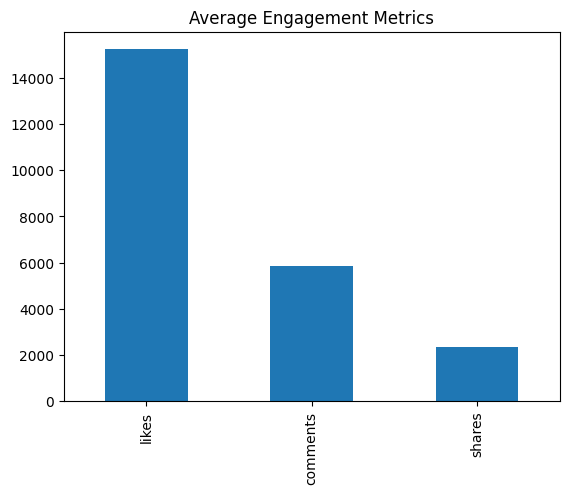

In [12]:
#Bar Chart – Likes, Comments, Shares

data[['likes','comments','shares']].mean().plot(kind='bar')
plt.title("Average Engagement Metrics")
plt.show()

#Identify which metric is strongest.

Hourly Engagement 

ax = hourly_likes.plot(...)
Stores the graph so we can add text on it.

enumerate() is a Python function used in loops to get:
The position (index)
The value at the same time.

for i, v in enumerate(hourly_likes):
i → position of the bar (0–23 hours)
v → total likes value for that hour

ax.text(i, v, str(v), ...)
text() is used to write words or numbers on the graph.

Places the number on top of each bar
i → x position
v → height of the bar

str(v) → shows the actual count

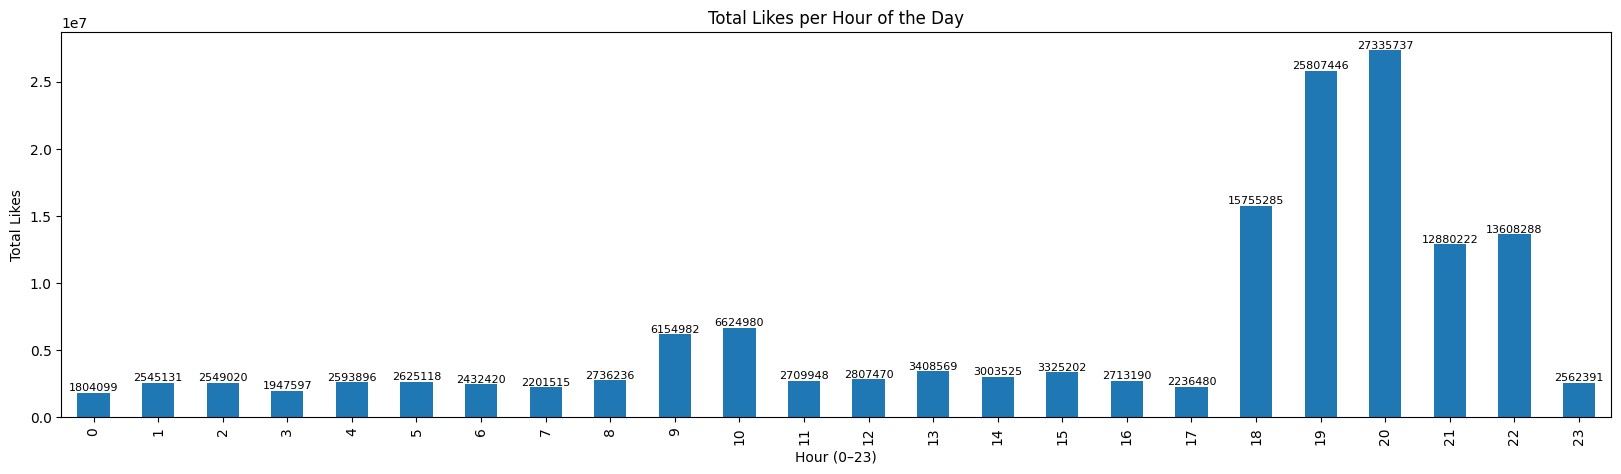

In [13]:
#converting the datatype

data["post_datetime"] = pd.to_datetime(data["post_datetime"])
#Extracting Hour from the date
data['Hour'] = data['post_datetime'].dt.hour
hourly_likes = data.groupby('Hour')['likes'].sum()

#plotting Graph
ax = hourly_likes.plot(kind='bar', figsize=(20,5))
plt.title("Total Likes per Hour of the Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Total Likes")
plt.xticks(range(0,24))

# Add count labels on each bar
for i, v in enumerate(hourly_likes):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)

plt.show()




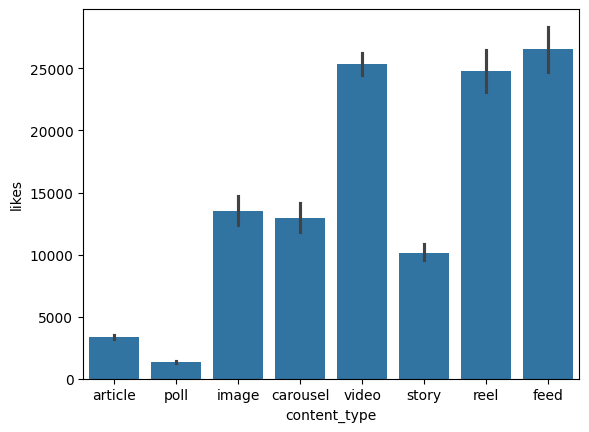

In [14]:
#Shows which post type gets more likes.
sns.barplot(x='content_type', y='likes', data=data)
plt.show()


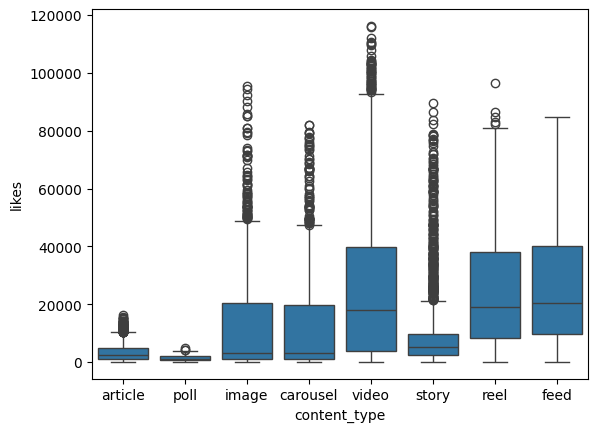

In [15]:
sns.boxplot(x='content_type', y='likes', data=data)
plt.show()


4) MODEL TRAINING
Step 1: Prepare Data

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['content_type'] = le.fit_transform(data['content_type'])



Step 2: Select Features

In [17]:
X = data[['views','likes','comments','shares','sentiment_score', 'engagement_rate']]	
y = data['is_viral']


In [18]:
print(X)

       views  likes  comments  shares  sentiment_score  engagement_rate
0      37781   1202       462     185             0.76           0.0490
1      23541   1399       538     215             0.46           0.0915
2      30714   1663       639     255            -0.01           0.0833
3      31294   1372       528     211             0.55           0.0675
4      43129   2234       859     343             0.70           0.0797
...      ...    ...       ...     ...              ...              ...
9995  430376  39279     15107    6043            -0.05           0.1404
9996  559223  12513      4812    1925             0.61           0.0344
9997  833212  31796     12229    4891             0.78           0.0587
9998  182707  15690      6034    2413             0.49           0.1321
9999  937825  33244     12786    5114            -0.99           0.0545

[10000 rows x 6 columns]


In [19]:
print(y)

0       0
1       1
2       1
3       0
4       0
       ..
9995    1
9996    0
9997    0
9998    1
9999    0
Name: is_viral, Length: 10000, dtype: int64


Step 3: Split Data

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)


In [21]:
X_train.shape

(8000, 6)

In [22]:
X_test.shape

(2000, 6)

In [23]:
y_train.shape

(8000,)

Step 4: Train Model

In [24]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Step 5: Testing


In [25]:
predictions = model.predict(X_test)


5) PERFORMANCE METRICS

In [26]:
from sklearn.metrics import accuracy_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, predictions))
print(confusion_matrix(y_test, predictions))


Accuracy: 0.9445
[[ 866   34]
 [  77 1023]]


TP = 992
Model correctly predicted viral posts.
FN = 64
Model missed viral posts.
FP = 47
Model wrongly predicted viral for non-viral posts.
TN = 897
Model correctly predicted non-viral posts.

In [27]:
new_data_1 = [[50000, 12000, 1500, 800, 0.85, 0.32]]
prediction1 = model.predict(new_data_1)
print(prediction1)

[1]


c:\Users\Lasya\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [28]:
new_data_2 = [[8000, 900, 60, 20, 0.20, 0.07]]
prediction2 = model.predict(new_data_2)
print(prediction2)


[0]


c:\Users\Lasya\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
